In [167]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [168]:
df = pd.read_csv("solar_system.csv")

In [169]:
df.shape


(20, 11)

In [170]:
#20 rows, 11 columns

In [171]:
print(df.head(5), df.tail(5))

                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3                     Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2       95      274   
18             Ring System?    

In [172]:
print(str(list(df.columns))[1:-1])

'Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter', 'Saturn', 'Uranus', 'Neptune', 'Pluto'


In [173]:
print(df.iloc[:,0]) #printing the row names

0                  Mass (10^24kg)
1                   Diameter (km)
2                Density (kg/m^3)
3                 Gravity (m/s^2)
4          Escape Velocity (km/s)
5         Rotation Period (hours)
6           Length of Day (hours)
7     Distance from Sun (10^6 km)
8            Perihelion (10^6 km)
9              Aphelion (10^6 km)
10          Orbital Period (days)
11        Orbital Velocity (km/s)
12      Orbital Inclination (deg)
13           Orbital Eccentricity
14       Obliquity to Orbit (deg)
15           Mean Temperature (C)
16        Surface Pressure (bars)
17                Number of Moons
18                   Ring System?
19         Global Magnetic Field?
Name: Attribute, dtype: str


In [174]:
orbit = df.iloc[10, 1:].astype(float)

In [175]:
orbit

Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: 10, dtype: float64

In [176]:
perihelion = df.iloc[8, 1:].astype(float)

In [177]:
perihelion

Mercury      46.000
Venus       107.500
Earth       147.100
Moon          0.363
Mars        206.700
Jupiter     740.600
Saturn     1357.600
Uranus     2732.700
Neptune    4471.100
Pluto      4436.800
Name: 8, dtype: float64

In [178]:
aphelion = df.iloc[9, 1:].astype(float)

Perihelion: The point in a planet's or object's orbit where it is closest to the Sun. At this point, the object moves at its highest speed due to the Sun's strong gravitational pull.

Aphelion: The point in a planet's or object's orbit where it is farthest away from the Sun. Here, the object moves at its slowest speed in its orbit.

Semi-major axis: Half of the longest diameter of an elliptical orbit. It represents the average distance between the orbiting object and the Sun, and can be calculated by taking the average of the perihelion and aphelion distances.

In [179]:
semi_major_axis = (perihelion + aphelion) / 2
semi_major_axis

Mercury      57.9000
Venus       108.2000
Earth       149.6000
Moon          0.3845
Mars        228.0000
Jupiter     778.5000
Saturn     1432.0500
Uranus     2867.0500
Neptune    4515.0000
Pluto      5906.3500
dtype: float64

In [180]:
sma = pd.Series(data=semi_major_axis, name="Semi-major Axis (in 10^6 km)")

In [181]:

df = pd.concat([df, sma.to_frame().T]) #to frame turns the 1D sma vektor to a 2D data frame with the planets as rows and the varaible as the only column, T transposes this to a "row vector" 

In [182]:
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [183]:
df.shape

(21, 11)

In [184]:
#21 rows, 11 columns

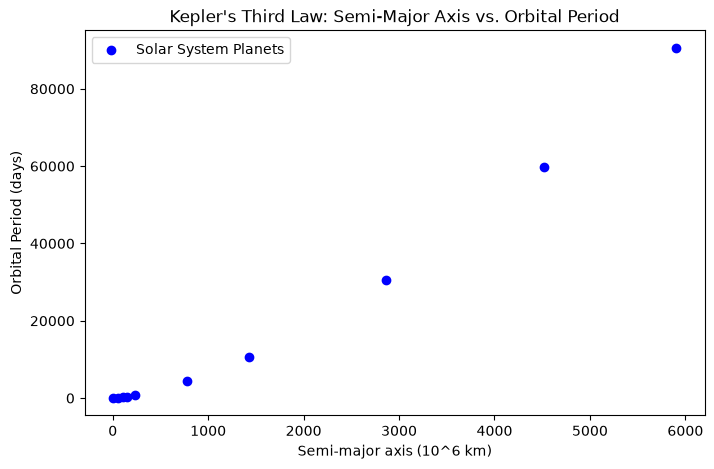

In [185]:
plt.figure(figsize=(8, 5))
plt.scatter(semi_major_axis, orbit, color="blue", label="Solar System Planets")
plt.xlabel("Semi-major axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Kepler's Third Law: Semi-Major Axis vs. Orbital Period")
plt.legend()
plt.show()

In [186]:
#11.

In [187]:
def keplers_third_law(a, m):
    return m * a ** 1.5

In [188]:
popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbit)
m_fit = popt
m_fit

array([0.19879982])

In [161]:
print(f"Fitted model: T = {m_fit:.2f} * a^1.5")

TypeError: unsupported format string passed to numpy.ndarray.__format__

In [162]:
residuals = orbit - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals**2)
dof = len(semi_major_axis) - len(popt)
chi2_reduced = chi2 / dof
print(f"Reduced chi-squared: {chi2_reduced}")

Reduced chi-squared: 41276.70608939402


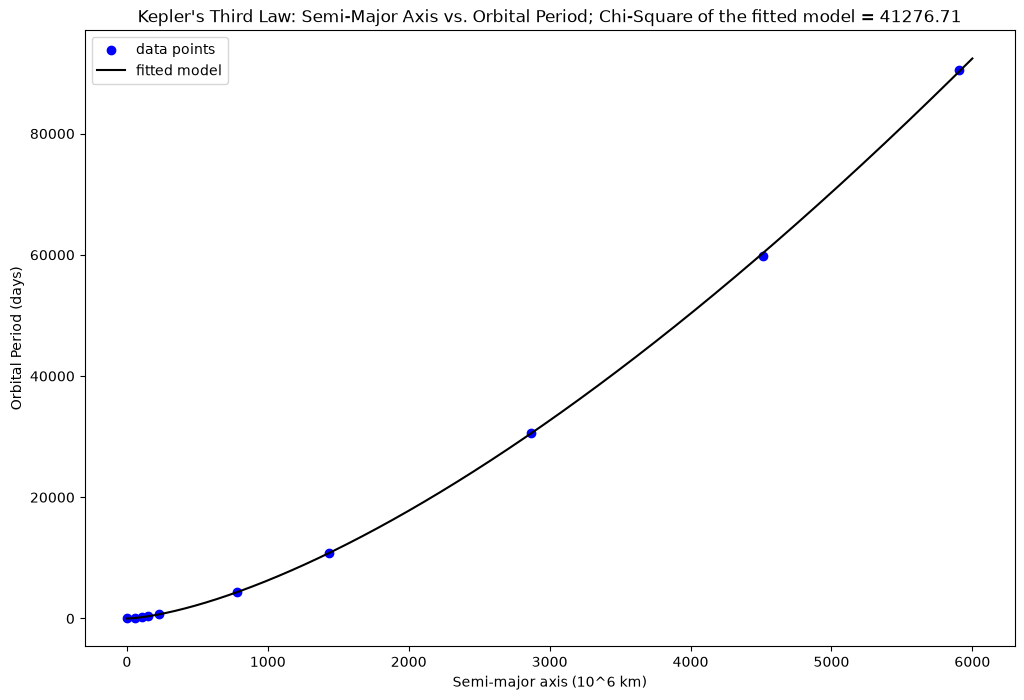

In [137]:
x = np.linspace(0, 6000, 100000)

plt.figure(figsize=(12,8))
plt.scatter(semi_major_axis, orbit, color="blue", label="data points")
plt.plot(x, keplers_third_law(x, m_fit), label = "fitted model", color = "black")
plt.xlabel("Semi-major axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title(f"Kepler's Third Law: Semi-Major Axis vs. Orbital Period; Chi-Square of the fitted model = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [138]:
df.to_csv("kepler.csv")